**GitHub repository:**
- https://github.com/ElishaSeruma/dataAnalyticsProject

**NFL Production Analysis**

# The research question
Among running backs, wide receivers and tight ends listed in the NFL Combine dataset, how are athletic based drill results and drill participation associated with regular-season offensive production over the first five seasons after entering the NFL?

- **Main analysis:** For each position, test whether results in drills like the 40-yard dash or broad jump correlate with five-year production. Use rushing plus receiving yards as your primary measure and touchdowns as a secondary measure.
- **Mini-analysis:** For each drill, compare players who recorded a result with those marked DNP. Look at their five-year production and draft position to see whether the groups differ.


#**Business Understanding**
##***What decisions or questions actually matter***

###*How is the NFL combine operated?*

The **NFL Scouting Combine** is an annual, invitation-only evaluation held in Indianapolis before the NFL Draft. It brings roughly 300 draft-eligible prospects to one place so all 32 NFL clubs can gather medical information, interview players, and assess their athletic ability under similar conditions. National Football Scouting (NFS) coordinates the event and distributes centrally collected information to the clubs. Each club uses that information to make its own draft decisions.

**1. Prospects are selected and invited.** NFL teams provide input on draft-eligible players, and a Player Selection Committee votes on which prospects to invite by position. The invitation process means the Combine is already a selected sample: it does not include every draft-eligible player. For example, the NFL listed 319 invitees in 2026. Being invited is also distinct from attending or completing a particular drill.

**2. Prospects go through medical evaluations and team interviews.** A medical advisory committee reviews players’ medical histories before they arrive. Prospects undergo standard examinations, and medical staff can request additional tests based on a player’s history, such as imaging for a previous knee injury. NFS compiles the findings into electronic medical records available to all 32 clubs. Teams also meet with prospects individually to ask about their football background, discuss how they read plays, and learn how they communicate and respond to feedback. These evaluations are a substantial part of the event even though fans mostly see the workouts.

**3. Prospects are measured and work out in position groups.** Staff record body measurements such as height and weight. On-field sessions are scheduled by position group at Lucas Oil Stadium. The standard athletic drills give teams a common way to compare particular abilities; position-specific drills let evaluators see how prospects move while performing football tasks. For example, a receiver’s 40-yard dash measures straight-line speed, while route-running and catching drills let scouts observe how the receiver changes direction and handles the ball.

| Athletic test | What it helps assess |
|---|---|
| 40-yard dash | Straight-line acceleration and speed; lower times are better |
| Vertical jump | Upward explosiveness |
| Broad jump | Horizontal explosiveness from a standing start |
| Three-cone drill | Ability to change direction while moving around a set course |
| 20-yard shuttle | Short-distance acceleration, braking, and change of direction |
| Bench press | Upper-body muscular endurance, measured in repetitions at 225 pounds |

**4. A player can attend without doing every drill.** Some prospects choose to skip individual tests or the entire on-field workout. Others may miss a test because of an injury. A player can still meet with teams in Indianapolis and work out later at a college **pro day**, a separate event hosted by the school. For an example relevant to offensive playmakers, wide receiver Malik Nabers skipped the 40-yard dash at the 2024 Combine and ran it later at LSU’s pro day. His lack of a Combine time did not mean scouts had no opportunity to see him run.

**5. Teams combine the results with their existing scouting work.** Clubs use the event to check what they have seen on college game film and investigate questions they still have about a player. A fast 40 may reinforce what scouts already saw from a wide receiver, while the medical exam or interview may answer a different question altogether. The Combine does not produce a league-wide score that determines draft order. Teams weigh the evidence alongside college performance, film, and other pre-draft evaluations.

###*What kind of data would be required to make an analyis on this question?*
To answer this question, I would need data on **NFL Combine performance, drill participation, and NFL production** for the same players.

The Combine data would need to include each player’s name, college, position, and Combine year, along with their results in drills such as the 40-yard dash, vertical jump, and broad jump. It would also need to show when a player **did not participate (`DNP`)** in a drill, since that is different from having a recorded score or a missing record. If I wanted to identify players who *chose* to skip a drill, I would need a separate source that confirms their reason.

 The NFL data would need to include each player’s entry year and regular-season statistics for the **first five seasons after entering the league**. I would use rushing and receiving yards to measure offensive production, with touchdowns as an additional measure. I would also need a reliable way to match players across the two datasets, ideally through a shared player ID or a verified match using details such as name, college, and year.

Finally, I would need enough information to distinguish a player who **recorded zero production** from one whose NFL record **could not be found or matched**. Otherwise, treating every unmatched player as having zero production could distort the results.

**DATA SOURCES:**
>https://www.kaggle.com/datasets/philiphyde1/nfl-stats-1999-2022

>https://www.kaggle.com/datasets/isaaksipple/nfl-combine-2000-2025

###*What specific group of players would this project be able to analyse?*

>This project would analyse **running backs (RBs), wide receivers (WRs), and tight ends (TEs) listed in the NFL Combine dataset** who entered the NFL between **2012 and 2021**. The NFL statistics end in 2025, so these entry years give each player a full five-season observation window, even if they did not play in all five seasons. For each drill, the project would include players with recorded results and examine those marked `DNP` separately.

I would focus on these three positions because **scrimmage yards (rushing yards plus receiving yards)** and **rushing and receiving touchdowns** are meaningful measures of production for all three. Those measures would miss much of what quarterbacks contribute through passing or offensive linemen contribute through blocking.

I would **analyse each position separately** because players have different roles and opportunities to accumulate yards. Running backs can gain yards through carries and catches, while wide receivers and tight ends gain most of their yards through catches. Combining the groups could make a drill appear related to production simply because one position tends to score differently on that drill and gets different opportunities on the field. Separating the groups lets me ask, for example, **whether faster wide receivers tend to produce more than other wide receivers**.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Data Understanding**

**Load the two datasets.** The Combine file contains prospect and drill records. The yearly player offense file contains production by player, team, season and season type. Both CSVs should be in `/content/data`.

In [4]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

DATA = Path("/content/data")
combine = pd.read_csv(DATA / "NFL_Combine_Since_2000.csv")
yearly = pd.read_csv(DATA / "yearly_player_stats_offense.csv")

**Inspect the Combine data.** I look at the first five records, the number of rows and columns, and the data type of each column.

In [5]:
display(combine.head())
print("Shape:", combine.shape)
display(combine.dtypes)

,First,Last,Position,School,Height,Weight,40-yd Dash,Vertical Jump,Bench Press,Broad Jump,3-Cone Drill,20-yd Shuttle,Drafted,Team,Round,Pick,Year
0,John,Abraham,OLB,South Carolina,76,252,4.55,DNP,DNP,DNP,DNP,DNP,Y,New York Jets,1.0,13.0,2000
1,Shaun,Alexander,RB,Alabama,72,218,4.58,DNP,DNP,DNP,DNP,DNP,Y,Seattle Seahawks,1.0,19.0,2000
2,Darnell,Alford,OT,Boston Col.,76,334,5.56,25,23,94,8.48,4.98,Y,Kansas City Chiefs,6.0,188.0,2000
3,Kyle,Allamon,TE,Texas Tech,74,253,4.97,29,DNP,104,7.29,4.49,N,NaN,NaN,NaN,2000
4,Rashard,Anderson,CB,Jackson State,74,206,4.55,34,DNP,123,7.18,4.15,Y,Carolina Panthers,1.0,23.0,2000


Shape: (8968, 17)


,0
First,object
Last,object
Position,object
School,object
Height,int64
Weight,int64
40-yd Dash,object
Vertical Jump,object
Bench Press,object
Broad Jump,object


**Inspect the yearly player data.** I check the full file dimensions, then look at the first few rows and types of the fields I need for the project.

In [6]:
production_cols = ["rushing_yards", "receiving_yards", "rush_touchdown", "receiving_touchdown"]
yearly_cols = [
    "player_id", "player_name", "position", "college_name", "rookie_season",
    "draft_year", "draft_round", "draft_pick", "season", "season_type", "team",
] + production_cols

print("Shape of full yearly file:", yearly.shape)
display(yearly[yearly_cols].head())
display(yearly[yearly_cols].dtypes)

Shape of full yearly file: (10856, 591)


,player_id,player_name,position,college_name,rookie_season,draft_year,draft_round,draft_pick,season,season_type,team,rushing_yards,receiving_yards,rush_touchdown,receiving_touchdown
0,00-0038389,Israel Abanikanda,RB,Pittsburgh,2023,2023.0,5.0,143.0,2023,REG,NYJ,70.0,43.0,0.0,0.0
1,00-0031021,Jared Abbrederis,WR,Wisconsin,2014,2014.0,5.0,176.0,2017,REG,DET,0.0,44.0,0.0,0.0
2,00-0031021,Jared Abbrederis,WR,Wisconsin,2014,2014.0,5.0,176.0,2015,POST,GB,0.0,69.0,0.0,0.0
3,00-0031021,Jared Abbrederis,WR,Wisconsin,2014,2014.0,5.0,176.0,2015,REG,GB,0.0,143.0,0.0,0.0
4,00-0031021,Jared Abbrederis,WR,Wisconsin,2014,2014.0,5.0,176.0,2016,REG,GB,0.0,8.0,0.0,0.0


,0
player_id,object
player_name,object
position,object
college_name,object
rookie_season,int64
draft_year,float64
draft_round,float64
draft_pick,float64
season,int64
season_type,object


**Check season coverage and position counts.** I count records by Combine year, NFL season and season type. I then preview the number of RB, WR and TE records for the proposed 2012–2021 cohorts. The NFL preview includes regular-season rows from rookie season through rookie season plus four. These are source row counts, not matched player counts.

In [7]:
display(combine["Year"].value_counts())
display(yearly["season"].value_counts())
display(yearly["season_type"].value_counts())

combine_scope = combine.loc[
    ((combine["Position"] == "RB") | (combine["Position"] == "WR") | (combine["Position"] == "TE"))
    & (combine["Year"] >= 2012) & (combine["Year"] <= 2021)
]
yearly_scope = yearly.loc[
    ((yearly["position"] == "RB") | (yearly["position"] == "WR") | (yearly["position"] == "TE"))
    & (yearly["season_type"] == "REG")
    & (yearly["rookie_season"] >= 2012) & (yearly["rookie_season"] <= 2021)
    & (yearly["season"] >= yearly["rookie_season"])
    & (yearly["season"] <= yearly["rookie_season"] + 4)
]

display(combine_scope.groupby("Position").size())
display(yearly_scope.groupby("position").size())

,count
Year,
2021,464
2020,337
2018,336
2019,336
2004,335
2014,333
2016,332
2013,332
2025,331


,count
season,
2021,850
2020,823
2022,803
2025,797
2024,792
2018,778
2019,772
2023,768
2015,761


,count
season_type,
REG,8908
POST,1948


,0
Position,
RB,305
TE,192
WR,488


,0
position,
RB,1165
TE,831
WR,1578


**Check missing values and drill participation.** I count blank values separately from explicit `DNP` entries. For a first look at participation by position, I use the 40-yard dash as an example. I keep the original drill values intact.

,0
40-yd Dash,0
Vertical Jump,0
Bench Press,0
Broad Jump,0
3-Cone Drill,0
20-yd Shuttle,0


,0
40-yd Dash,77
Vertical Jump,138
Bench Press,215
Broad Jump,166
3-Cone Drill,359
20-yd Shuttle,333


,0
rushing_yards,0
receiving_yards,0
rush_touchdown,0
receiving_touchdown,0


,0
Position,
RB,16
TE,22
WR,39


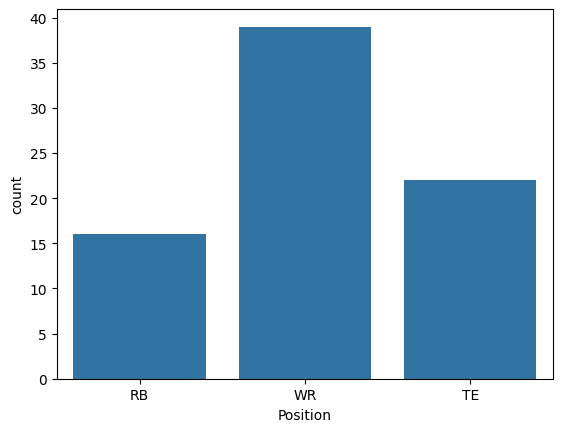

In [8]:
drills = ["40-yd Dash", "Vertical Jump", "Bench Press", "Broad Jump", "3-Cone Drill", "20-yd Shuttle"]
display(combine_scope[drills].isnull().sum())
display((combine_scope[drills] == "DNP").sum())
display(yearly_scope[production_cols].isnull().sum())

dash_dnp = combine_scope.loc[combine_scope["40-yd Dash"] == "DNP"]
display(dash_dnp.groupby("Position").size())
sns.countplot(data=dash_dnp, x="Position", order=["RB", "WR", "TE"])
plt.show()

**Summarise production and inspect one drill.** The summary describes individual yearly records before aggregation. I use the class example of converting a text field to numeric on a separate 40-yard dash series so I can plot recorded times without overwriting `DNP`.

,count,mean,std,min,25%,50%,75%,max
rushing_yards,3574.0,108.120593,258.134887,-49.0,0.00,0.0,51.0,2089.0
receiving_yards,3574.0,235.884163,301.854960,-7.0,26.25,114.0,322.0,1962.0
rush_touchdown,3574.0,0.797146,2.240128,0.0,0.00,0.0,0.0,21.0
receiving_touchdown,3574.0,1.502798,2.434100,0.0,0.00,0.0,2.0,17.0


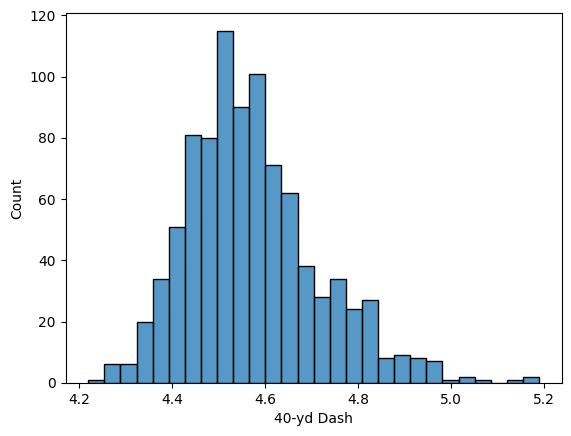

In [9]:
display(yearly_scope[production_cols].describe().T)
dash_times = pd.to_numeric(combine_scope["40-yd Dash"], errors="coerce")
sns.histplot(dash_times, kde=False)
plt.show()

**Data Preparation**

**Modelling**

**Evaluation**

**Deployment(*)**